In [1]:

!pip install -q pandas numpy requests beautifulsoup4 nltk scikit-learn matplotlib gradio joblib

print("All required libraries are ready!")



All required libraries are ready!


In [2]:

import pandas as pd
import numpy as np
import requests
import re
import nltk
import matplotlib.pyplot as plt
import joblib
import gradio as gr

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

# Keep important negation words
important_words = {"not", "no", "nor", "never"}
stop_words = stop_words - important_words

stemmer = PorterStemmer()

def preprocess_text(text):
    text = str(text).lower()

    # Remove URLs and user mentions
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)

    # Preserve the meaning of common negation contractions
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bn't\b", " not", text)

    # Keep only English letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()

    # Remove stopwords but retain negation words
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

print("Improved preprocessing function is ready!")

print(preprocess_text("I am not happy with this terrible result."))
print(preprocess_text("I never liked this product."))
print(preprocess_text("I love this amazing product!"))


Improved preprocessing function is ready!
not happi terribl result
never like product
love amaz product


In [5]:

import pandas as pd
import requests
from io import StringIO

base_url = (
    "https://raw.githubusercontent.com/"
    "cardiffnlp/tweeteval/main/datasets/sentiment/"
)

def load_text_file(filename):
    url = base_url + filename
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    # Each line is one text sample; preserve internal tabs
    lines = response.text.splitlines()
    return pd.DataFrame({"text": lines})

def load_label_file(filename):
    url = base_url + filename
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    labels = response.text.splitlines()
    return pd.DataFrame({
        "label": [int(label.strip()) for label in labels]
    })

# Training dataset
train_df = load_text_file("train_text.txt")
train_df["label"] = load_label_file("train_labels.txt")["label"]

# Validation dataset
val_df = load_text_file("val_text.txt")
val_df["label"] = load_label_file("val_labels.txt")["label"]

# Test dataset
test_df = load_text_file("test_text.txt")
test_df["label"] = load_label_file("test_labels.txt")["label"]

label_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

for df in [train_df, val_df, test_df]:
    df["sentiment"] = df["label"].map(label_map)

print("Dataset downloaded successfully!")
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTraining data preview:")
display(train_df.head())

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())


Dataset downloaded successfully!
Training samples: 45615
Validation samples: 2000
Test samples: 12284

Training data preview:


,text,label,sentiment
0,"""QT @user In the original draft of the 7th boo...",2,Positive
1,"""Ben Smith / Smith (concussion) remains out of...",1,Neutral
2,Sorry bout the stream last night I crashed out...,1,Neutral
3,Chase Headley's RBI double in the 8th inning o...,1,Neutral
4,@user Alciato: Bee will invest 150 million in ...,2,Positive



Sentiment distribution:
sentiment
Neutral     20673
Positive    17849
Negative     7093
Name: count, dtype: int64


In [6]:

def clean_dataset(df):
    df = df.copy()

    # Remove missing values
    df = df.dropna(subset=["text", "label"])

    # Convert text to string and remove extra spaces
    df["text"] = df["text"].astype(str).str.strip()

    # Remove empty text
    df = df[df["text"] != ""]

    # Remove duplicate text
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

    # Restore readable sentiment labels
    label_map = {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }
    df["sentiment"] = df["label"].map(label_map)

    return df


# Clean each dataset separately
train_clean = clean_dataset(train_df)
val_clean = clean_dataset(val_df)
test_clean = clean_dataset(test_df)

print("Training samples after cleaning:", len(train_clean))
print("Validation samples after cleaning:", len(val_clean))
print("Test samples after cleaning:", len(test_clean))


Training samples after cleaning: 45586
Validation samples after cleaning: 2000
Test samples after cleaning: 12284


In [7]:

# Apply the preprocessing function defined in Step 2

train_clean["clean_text"] = train_clean["text"].apply(preprocess_text)
val_clean["clean_text"] = val_clean["text"].apply(preprocess_text)
test_clean["clean_text"] = test_clean["text"].apply(preprocess_text)

# Remove samples that become empty after preprocessing
train_clean = train_clean[
    train_clean["clean_text"].str.strip() != ""
].reset_index(drop=True)

val_clean = val_clean[
    val_clean["clean_text"].str.strip() != ""
].reset_index(drop=True)

test_clean = test_clean[
    test_clean["clean_text"].str.strip() != ""
].reset_index(drop=True)

print("Text preprocessing completed successfully!")

print("\nOriginal text:")
print(train_clean["text"].iloc[0])

print("\nPreprocessed text:")
print(train_clean["clean_text"].iloc[0])

print("\nFinal dataset sizes:")
print("Training:", len(train_clean))
print("Validation:", len(val_clean))
print("Testing:", len(test_clean))


Text preprocessing completed successfully!

Original text:
"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"

Preprocessed text:
qt origin draft th book remu lupin surviv battl hogwart happybirthdayremuslupin

Final dataset sizes:
Training: 45586
Validation: 2000
Testing: 12282


In [8]:

train_clean.to_csv(
    "cleaned_sentiment_training_dataset.csv",
    index=False,
    encoding="utf-8"
)

print("Cleaned training dataset saved successfully!")
display(train_clean[["text", "clean_text", "sentiment"]].head(5))


Cleaned training dataset saved successfully!


,text,clean_text,sentiment
0,"""QT @user In the original draft of the 7th boo...",qt origin draft th book remu lupin surviv batt...,Positive
1,"""Ben Smith / Smith (concussion) remains out of...",ben smith smith concuss remain lineup thursday...,Neutral
2,Sorry bout the stream last night I crashed out...,sorri bout stream last night crash tonight sur...,Neutral
3,Chase Headley's RBI double in the 8th inning o...,chase headley rbi doubl th inning david price ...,Neutral
4,@user Alciato: Bee will invest 150 million in ...,alciato bee invest million januari anoth summe...,Positive


In [9]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn vocabulary only from training data
X_train_tfidf = tfidf_vectorizer.fit_transform(
    train_clean["clean_text"]
)

# Transform validation and test data without refitting
X_val_tfidf = tfidf_vectorizer.transform(
    val_clean["clean_text"]
)

X_test_tfidf = tfidf_vectorizer.transform(
    test_clean["clean_text"]
)

# Prepare labels
y_train = train_clean["label"]
y_val = val_clean["label"]
y_test = test_clean["label"]

print("TF-IDF vectorization completed!")
print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)
print("Number of features:", len(tfidf_vectorizer.get_feature_names_out()))


TF-IDF vectorization completed!
Training matrix: (45586, 15000)
Validation matrix: (2000, 15000)
Test matrix: (12282, 15000)
Number of features: 15000


In [10]:

feature_names = tfidf_vectorizer.get_feature_names_out()

print("First 30 TF-IDF features:")
print(feature_names[:30])

print("\nSample TF-IDF matrix:")
display(
    pd.DataFrame(
        X_train_tfidf[:5, :10].toarray(),
        columns=feature_names[:10]
    ).round(3)
)


First 30 TF-IDF features:
['aa' 'aaah' 'aacta' 'aaliyah' 'aaliyah th' 'aapl' 'aaron' 'aaron rodger'
 'aaron samuel' 'ab' 'ab cbn' 'abandon' 'abbey' 'abbey dawn' 'abbi'
 'abbott' 'abc' 'abc sunday' 'abil' 'abj' 'abl' 'abl buy' 'abl get'
 'abl see' 'abl watch' 'ablett' 'abort' 'abou' 'abramovich' 'abreu']

Sample TF-IDF matrix:


,aa,aaah,aacta,aaliyah,aaliyah th,aapl,aaron,aaron rodger,aaron samuel,ab
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:

import joblib

joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")
print("TF-IDF vectorizer saved successfully!")


TF-IDF vectorizer saved successfully!


In [12]:

from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB(alpha=0.5)

nb_model.fit(X_train_tfidf, y_train)

nb_val_predictions = nb_model.predict(X_val_tfidf)

print("Naive Bayes training completed!")


Naive Bayes training completed!


In [13]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    C=2.0,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_val_predictions = lr_model.predict(X_val_tfidf)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [14]:

from sklearn.metrics import accuracy_score, f1_score

nb_val_accuracy = accuracy_score(y_val, nb_val_predictions)
lr_val_accuracy = accuracy_score(y_val, lr_val_predictions)

nb_val_f1 = f1_score(
    y_val, nb_val_predictions, average="weighted"
)
lr_val_f1 = f1_score(
    y_val, lr_val_predictions, average="weighted"
)

validation_results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Validation Accuracy (%)": [
        round(nb_val_accuracy * 100, 2),
        round(lr_val_accuracy * 100, 2)
    ],
    "Weighted F1 (%)": [
        round(nb_val_f1 * 100, 2),
        round(lr_val_f1 * 100, 2)
    ]
})

display(validation_results)


,Model,Validation Accuracy (%),Weighted F1 (%)
0,Naive Bayes,63.05,61.60
1,Logistic Regression,66.90,66.43


In [15]:

from sklearn.metrics import classification_report

label_names = ["Negative", "Neutral", "Positive"]

print("===== NAIVE BAYES =====")
print(classification_report(
    y_val,
    nb_val_predictions,
    labels=[0, 1, 2],
    target_names=label_names,
    zero_division=0
))

print("===== LOGISTIC REGRESSION =====")
print(classification_report(
    y_val,
    lr_val_predictions,
    labels=[0, 1, 2],
    target_names=label_names,
    zero_division=0
))


===== NAIVE BAYES =====
              precision    recall  f1-score   support

    Negative       0.56      0.24      0.33       312
     Neutral       0.60      0.72      0.66       869
    Positive       0.68      0.68      0.68       819

    accuracy                           0.63      2000
   macro avg       0.61      0.55      0.56      2000
weighted avg       0.63      0.63      0.62      2000

===== LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

    Negative       0.59      0.41      0.48       312
     Neutral       0.65      0.72      0.68       869
    Positive       0.72      0.71      0.71       819

    accuracy                           0.67      2000
   macro avg       0.65      0.61      0.63      2000
weighted avg       0.67      0.67      0.66      2000



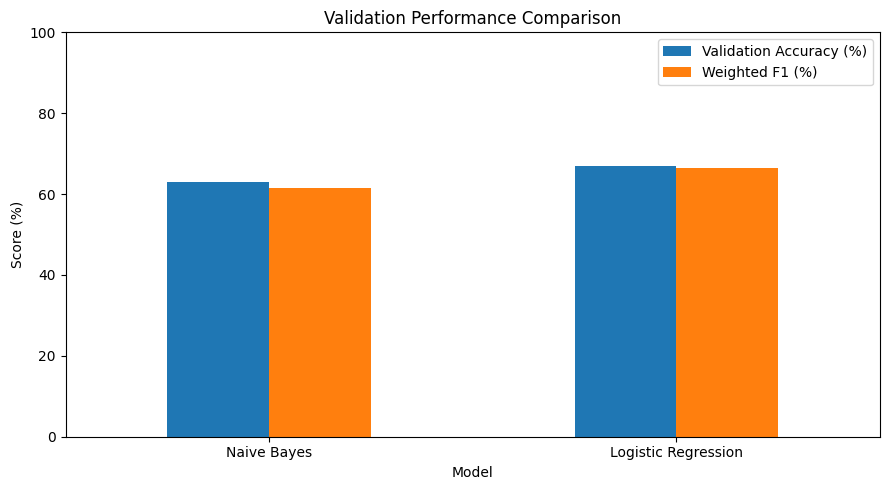

In [16]:

import matplotlib.pyplot as plt

validation_results.set_index("Model")[
    ["Validation Accuracy (%)", "Weighted F1 (%)"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Validation Performance Comparison")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [17]:

if nb_val_f1 >= lr_val_f1:
    best_model = nb_model
    best_model_name = "Naive Bayes"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("Selected model:", best_model_name)
print("Selection based on weighted F1-score on validation data.")


Selected model: Logistic Regression
Selection based on weighted F1-score on validation data.


In [18]:

from sklearn.metrics import accuracy_score, f1_score, classification_report

test_predictions = best_model.predict(X_test_tfidf)

test_accuracy = accuracy_score(y_test, test_predictions)
test_weighted_f1 = f1_score(
    y_test, test_predictions, average="weighted"
)

print("Selected model:", best_model_name)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Weighted F1-score:", round(test_weighted_f1 * 100, 2), "%")

print("\nDetailed Test Classification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))


Selected model: Logistic Regression
Test Accuracy: 60.42 %
Weighted F1-score: 60.23 %

Detailed Test Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.49      0.56      3972
     Neutral       0.62      0.68      0.65      5935
    Positive       0.52      0.61      0.56      2375

    accuracy                           0.60     12282
   macro avg       0.60      0.59      0.59     12282
weighted avg       0.61      0.60      0.60     12282



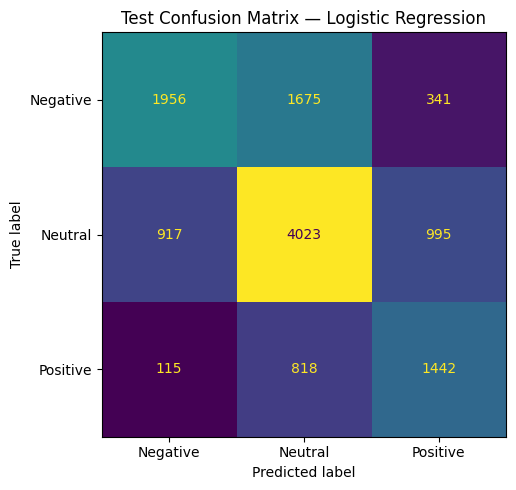

In [20]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1, 2]
)

# Set figure size separately
fig, ax = plt.subplots(figsize=(7, 5))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display_cm.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(f"Test Confusion Matrix — {best_model_name}")

plt.tight_layout()
plt.show()


In [21]:

import joblib

joblib.dump(best_model, "best_sentiment_model.pkl")
joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")

print("Selected model and TF-IDF vectorizer saved successfully!")


Selected model and TF-IDF vectorizer saved successfully!


In [22]:

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

label_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

def predict_sentiment(text):
    if not text or not text.strip():
        return "Please enter some text."

    cleaned_text = preprocess_text(text)

    if not cleaned_text.strip():
        return "Please enter meaningful English text."

    features = tfidf_vectorizer.transform([cleaned_text])

    prediction = int(best_model.predict(features)[0])
    probabilities = best_model.predict_proba(features)[0]

    sentiment = label_map[prediction]
    confidence = max(probabilities) * 100

    return (
        f"Predicted Sentiment: {sentiment}\n"
        f"Model Confidence: {confidence:.2f}%"
    )


def create_sentiment_chart():
    sample_sentences = [
        "I absolutely love this amazing product!",
        "This is a terrible and disappointing experience.",
        "The meeting is scheduled for tomorrow."
    ]

    predictions = [
        predict_sentiment(sentence)
        for sentence in sample_sentences
    ]

    # Display live news distribution if available
    if "updated_live_df" in globals() and not updated_live_df.empty:
        counts = (
            updated_live_df["predicted_sentiment"]
            .value_counts()
            .reindex(["Negative", "Neutral", "Positive"], fill_value=0)
        )
    else:
        counts = pd.Series(
            [0, 0, 0],
            index=["Negative", "Neutral", "Positive"]
        )

    fig, ax = plt.subplots(figsize=(7, 4))
    counts.plot(kind="bar", ax=ax)
    ax.set_title("Live News Sentiment Distribution")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Number of Headlines")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()

    return fig


with gr.Blocks(title="Real-Time Sentiment Analysis") as demo:
    gr.Markdown("# Real-Time Sentiment Analysis System")
    gr.Markdown(
        f"Selected model: **{best_model_name}**"
    )

    with gr.Tab("Text Prediction"):
        input_text = gr.Textbox(
            label="Enter a sentence",
            placeholder="Example: I am very happy today."
        )

        predict_button = gr.Button("Predict Sentiment")
        output_text = gr.Textbox(label="Prediction Result")

        predict_button.click(
            fn=predict_sentiment,
            inputs=input_text,
            outputs=output_text
        )

    with gr.Tab("News Dashboard"):
        chart = gr.Plot(label="BBC News Sentiment Distribution")

        refresh_button = gr.Button("Refresh Chart")
        refresh_button.click(
            fn=create_sentiment_chart,
            inputs=None,
            outputs=chart
        )

        gr.Markdown(
            "The chart shows the sentiment distribution from the latest "
            "news data already loaded into the notebook."
        )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://91796ee7216c4379d7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
